# Engagement & Churn Drivers

**Purpose:** Join usage to subscriptions, build first-month engagement features, rank the top churn drivers with a Cox model, check that each driver holds within tenure bands, test sensitivity to the 139 flagged customers, and compare stated cancel reasons with actual behaviour.

**Inputs:** `data/processed/subscriptions_model.csv`, `data/processed/usage_clean.csv`
**Outputs:** `data/processed/customer_features.csv`, `reports/cox_hazard_ratios.csv`, `reports/figures/05_cox_hazard_ratios.png`

**Method notes**
- **First-month features** come from each customer's sign-up month of usage.
- **Landmark analysis:** only customers still subscribed at day 31 are analysed, so first-month behaviour can't be influenced by a later cancellation (no "peeking").
- **Cox model, stratified by plan type:** annual plans have a renewal cliff that breaks the model's constant-effect assumption, so monthly and annual plans each get their own baseline.
- **Hazard ratio (HR):** 1.5 means a 50% higher cancellation rate than the reference group.

Importing libraries, setting paths, and loading the subscriptions and usage tables.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

PROC = Path("../data/processed")
REPORTS = Path("../reports")
FIG = REPORTS / "figures"

subs = pd.read_csv(PROC / "subscriptions_model.csv", parse_dates=["signup_date", "churn_date", "end_date"])
usage = pd.read_csv(PROC / "usage_clean.csv")
print("subscriptions:", subs.shape, "| usage:", usage.shape)

subscriptions: (4200, 23) | usage: (30525, 8)


Building first-month engagement features from the sign-up month and grouping customers into low, mid and high engagement.

In [11]:
first = (usage.sort_values("month").groupby("customer_id").first().reset_index()
         [["customer_id", "workouts_completed", "minutes_active", "classes_booked", "support_tickets", "classes_eligible"]]
         .rename(columns={"workouts_completed": "first_workouts", "minutes_active": "first_minutes",
                          "classes_booked": "first_classes", "support_tickets": "first_tickets"}))

d = subs.merge(first, on="customer_id")
d["engagement"] = pd.cut(d.first_workouts, [-1, 2, 5, 1000], labels=["low (0-2)", "mid (3-5)", "high (6+)"])

print("customers by first-month engagement:")
print(d.engagement.value_counts().sort_index().to_string())
print("\nfirst-month support tickets:", d.first_tickets.value_counts().sort_index().to_dict())

customers by first-month engagement:
engagement
low (0-2)    1765
mid (3-5)    1389
high (6+)    1046

first-month support tickets: {0: 3829, 1: 358, 2: 13}


Creating the landmark analysis set: only customers still subscribed at day 31, so first-month behaviour can't be influenced by a later cancellation.

In [12]:
LANDMARK = 31      # the sign-up month never lasts longer than 31 days, so its usage is fully known by then

lm = d[d.duration_days > LANDMARK].copy()
lm["t"] = lm.duration_days - LANDMARK      # time measured from the landmark
lm["e"] = lm.event

print("all customers                         :", len(d))
print("left before day 31 (excluded)         :", len(d) - len(lm))
print("analysed                              :", len(lm))
print("cancellations in analysed group       :", lm.e.sum())
print("flagged 'usage stopped early' in group:", lm.usage_stopped_early.sum())

all customers                         : 4200
left before day 31 (excluded)         : 279
analysed                              : 3921
cancellations in analysed group       : 1489
flagged 'usage stopped early' in group: 139


Comparing retention by first-month engagement, separately for monthly and annual plans.

In [13]:
def km_at(g, t):
    return float(KaplanMeierFitter().fit(g.t, g.e).survival_function_at_times(t).iloc[0])

rows = []
for (plan, eng), g in lm.groupby(["plan_type", "engagement"], observed=True):
    rows.append({
        "plan_type": plan,
        "engagement": eng,
        "customers": len(g),
        "retained_day_90": km_at(g, 90 - LANDMARK),
        "retained_day_180": km_at(g, 180 - LANDMARK),
    })
pd.DataFrame(rows).round(3)

,plan_type,engagement,customers,retained_day_90,retained_day_180
0,annual,low (0-2),647,0.973,0.935
1,annual,mid (3-5),499,0.996,0.968
2,annual,high (6+),377,0.995,0.995
3,monthly,low (0-2),943,0.722,0.535
4,monthly,mid (3-5),816,0.824,0.635
5,monthly,high (6+),639,0.909,0.816


Checking how engagement differs by acquisition channel, which may explain why some channels retain better.

In [14]:
(d.groupby("acquisition_channel")
   .agg(customers=("customer_id", "size"),
        avg_first_workouts=("first_workouts", "mean"),
        pct_low_engagement=("first_workouts", lambda x: (x <= 2).mean() * 100))
   .round(1))

,customers,avg_first_workouts,pct_low_engagement
acquisition_channel,,,
organic,1298,4.0,41.8
paid_social,989,4.0,40.7
partner,476,4.1,40.8
promo_offer,949,3.3,51.1
referral,488,5.1,28.7


Defining helpers that turn customers into model inputs (dummy columns) and fit a Cox model stratified by plan type.

In [15]:
def build_X(df):
    X = pd.DataFrame({"t": df.t, "e": df.e, "plan_type": df.plan_type})
    X["workouts_0"] = (df.first_workouts == 0).astype(int)
    X["workouts_1_2"] = df.first_workouts.between(1, 2).astype(int)
    X["workouts_6plus"] = (df.first_workouts >= 6).astype(int)
    X["any_ticket"] = (df.first_tickets > 0).astype(int)
    X["booked_class"] = ((df.first_classes > 0) & df.classes_eligible).astype(int)
    for c in ["paid_social", "partner", "promo_offer", "referral"]:
        X[f"channel_{c}"] = (df.acquisition_channel == c).astype(int)
    for c in ["android", "web"]:
        X[f"device_{c}"] = (df.primary_device == c).astype(int)
    for c in ["plus", "premium"]:
        X[f"tier_{c}"] = (df.plan_tier == c).astype(int)
    for c, name in [("18-24", "18_24"), ("35-44", "35_44"), ("45-54", "45_54"), ("55+", "55plus")]:
        X[f"age_{name}"] = (df.age_group == c).astype(int)
    return X

def fit_cox(X):
    cph = CoxPHFitter().fit(X, "t", "e", strata=["plan_type"])   # separate baseline for monthly and annual plans
    hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
    hr.columns = ["HR", "lo_95", "hi_95", "p_value"]
    return cph, hr.round(3)

Fitting the main model. HR is the hazard ratio, where 1.5 means a 50% higher cancellation rate than the reference group.

In [16]:
X = build_X(lm)
cph, hr = fit_cox(X)
print("customers:", len(X), "| cancellations:", int(X.e.sum()), "| concordance:", round(cph.concordance_index_, 3))
print("reference groups: 3-5 workouts, organic channel, ios, basic tier, age 25-34\n")
hr

customers: 3921 | cancellations: 1489 | concordance: 0.644
reference groups: 3-5 workouts, organic channel, ios, basic tier, age 25-34



,HR,lo_95,hi_95,p_value
covariate,,,,
workouts_0,1.844,1.537,2.212,0.000
workouts_1_2,1.413,1.250,1.597,0.000
workouts_6plus,0.538,0.459,0.629,0.000
any_ticket,0.878,0.730,1.055,0.164
booked_class,0.941,0.807,1.098,0.441
channel_paid_social,1.067,0.925,1.232,0.374
channel_partner,1.136,0.949,1.360,0.165
channel_promo_offer,1.562,1.363,1.790,0.000
channel_referral,0.950,0.787,1.146,0.589


Testing whether the "constant effect over time" assumption holds, and listing any variables that break it.

In [17]:
ph = proportional_hazard_test(cph, X, time_transform="rank")
ph_table = ph.summary[["test_statistic", "p"]].round(3)
print("variables whose effect changes over tenure (p < 0.05):")
ph_table[ph_table.p < 0.05]

variables whose effect changes over tenure (p < 0.05):


,test_statistic,p
workouts_0,6.301,0.012
workouts_1_2,10.658,0.001


Drawing a forest plot of the hazard ratios (red means statistically significant).

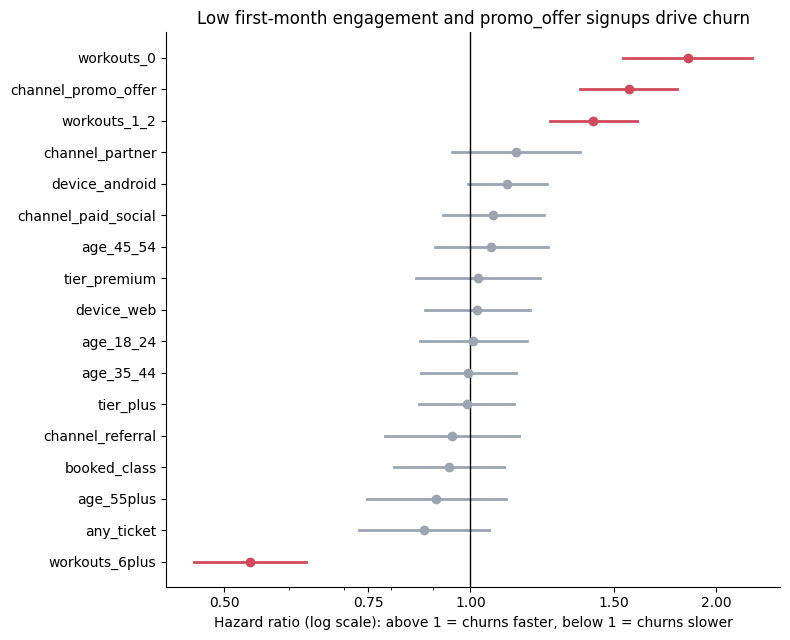

In [18]:
plot_df = hr.sort_values("HR")
fig, ax = plt.subplots(figsize=(8, 6.5))
for i, (name, r) in enumerate(plot_df.iterrows()):
    color = "#D1495B" if r.p_value < 0.05 else "#9AA5B1"
    ax.plot([r.lo_95, r.hi_95], [i, i], color=color, lw=2)
    ax.scatter(r.HR, i, color=color, zorder=3)

ax.axvline(1, color="black", lw=1)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())   # hide the stray minor tick labels
ax.set_xlabel("Hazard ratio (log scale): above 1 = churns faster, below 1 = churns slower")
ax.set_title("Low first-month engagement and promo_offer signups drive churn")
fig.tight_layout()
fig.savefig(FIG / "05_cox_hazard_ratios.png", dpi=150)
plt.show()

Checking that each driver holds within tenure bands (cancellations per 100 customer-months), for monthly and annual plans.

In [19]:
lm["channel_group"] = np.where(lm.acquisition_channel == "promo_offer", "promo_offer", "other channels")

def band_rates(df, group, bands):
    """Cancellations per 100 customer-months of exposure inside each tenure band (days since signup)."""
    out = {}
    for lo, hi in bands:
        col = {}
        for g, x in df.groupby(group, observed=True):
            exposure_days = (x.duration_days.clip(lower=lo, upper=hi) - lo).sum()
            events = ((x.event == 1) & (x.duration_days > lo) & (x.duration_days <= hi)).sum()
            col[g] = events / exposure_days * 30 * 100
        out[f"days {lo}-{hi}"] = col
    return pd.DataFrame(out).round(1)

monthly_bands = [(31, 90), (90, 180), (180, 365)]
annual_bands = [(31, 270), (270, 365)]
M, A = lm[lm.plan_type == "monthly"], lm[lm.plan_type == "annual"]

print("MONTHLY plans, by first-month engagement\n", band_rates(M, "engagement", monthly_bands), "\n")
print("MONTHLY plans, by channel\n", band_rates(M, "channel_group", monthly_bands), "\n")
print("ANNUAL plans, by first-month engagement\n", band_rates(A, "engagement", annual_bands), "\n")
print("ANNUAL plans, by channel\n", band_rates(A, "channel_group", annual_bands))

MONTHLY plans, by first-month engagement
            days 31-90  days 90-180  days 180-365
low (0-2)        16.6         10.3           8.3
mid (3-5)         9.8          8.8           6.6
high (6+)         4.8          3.6           3.8 

MONTHLY plans, by channel
                 days 31-90  days 90-180  days 180-365
other channels         7.9          7.3           6.3
promo_offer           23.1          9.5           5.2 

ANNUAL plans, by first-month engagement
            days 31-270  days 270-365
low (0-2)          1.3          28.7
mid (3-5)          0.6          15.7
high (6+)          0.3          11.6 

ANNUAL plans, by channel
                 days 31-270  days 270-365
other channels          0.8          18.5
promo_offer             1.0          23.1


Sensitivity check: re-running the model with the 139 flagged customers treated as churned right after day 31, and again with them excluded.

In [20]:
flag = lm.usage_stopped_early

alt = lm.copy()
alt.loc[flag, "t"] = 1       # cancelled one day after the landmark
alt.loc[flag, "e"] = 1
_, hr_alt = fit_cox(build_X(alt))
_, hr_excl = fit_cox(build_X(lm[~flag]))

key = ["workouts_0", "workouts_1_2", "workouts_6plus", "channel_promo_offer",
       "channel_referral", "any_ticket", "device_android"]
sens = pd.DataFrame({"main": hr.HR, "flagged_as_churned": hr_alt.HR, "flagged_excluded": hr_excl.HR}).loc[key]
print("cancellations: main =", int(lm.e.sum()), "| flagged as churned =", int(alt.e.sum()))
sens

cancellations: main = 1489 | flagged as churned = 1628


,main,flagged_as_churned,flagged_excluded
covariate,,,
workouts_0,1.844,2.340,2.224
workouts_1_2,1.413,1.606,1.540
workouts_6plus,0.538,0.528,0.527
channel_promo_offer,1.562,1.612,1.643
channel_referral,0.950,1.028,0.983
any_ticket,0.878,1.138,1.010
device_android,1.110,1.092,1.111


Comparing what churners say (cancel reason) with what they do (behaviour), for the groups our analysis flagged.

In [21]:
c = d[d.churned & (d.cancel_reason != "not_provided")].copy()      # only churners who gave a reason

groups = {
    "all churners": c.index == c.index,
    "promo_offer": c.acquisition_channel == "promo_offer",
    "other channels": c.acquisition_channel != "promo_offer",
    "low engagement": c.first_workouts <= 2,
    "mid/high engagement": c.first_workouts > 2,
    "had support ticket": c.first_tickets > 0,
    "no support ticket": c.first_tickets == 0,
}
reasons = pd.DataFrame({name: c[mask].cancel_reason.value_counts(normalize=True).mul(100)
                        for name, mask in groups.items()}).fillna(0).round(1)

print("churners who gave a reason:", len(c), "of", int(d.churned.sum()))
print("group sizes:", {name: int(mask.sum()) for name, mask in groups.items()}, "\n")
reasons.sort_values("all churners", ascending=False)

churners who gave a reason: 1386 of 1768
group sizes: {'all churners': 1386, 'promo_offer': 373, 'other channels': 1013, 'low engagement': 729, 'mid/high engagement': 657, 'had support ticket': 129, 'no support ticket': 1257} 



,all churners,promo_offer,other channels,low engagement,mid/high engagement,had support ticket,no support ticket
cancel_reason,,,,,,,
not_using_enough,41.1,38.6,42.1,48.6,32.9,38.8,41.4
too_expensive,23.2,36.7,18.3,20.3,26.5,18.6,23.7
found_alternative,12.6,7.0,14.7,11.7,13.7,7.8,13.1
other,11.7,5.9,13.8,9.2,14.5,11.6,11.7
technical_issues,11.3,11.8,11.2,10.3,12.5,23.3,10.1


Saving the customer-level feature table and the hazard ratios for the next notebooks and the dashboard.

In [22]:
features = d[["customer_id", "first_workouts", "first_minutes", "first_classes", "first_tickets", "engagement"]].copy()
features["in_landmark_set"] = d.duration_days > LANDMARK
features.to_csv(PROC / "customer_features.csv", index=False)
hr.to_csv(REPORTS / "cox_hazard_ratios.csv")

print("customer_features:", features.shape, "| in landmark set:", int(features.in_landmark_set.sum()))
print("saved: reports/cox_hazard_ratios.csv,", sorted(p.name for p in FIG.glob("05*.png")))

customer_features: (4200, 7) | in landmark set: 3921
saved: reports/cox_hazard_ratios.csv, ['05_cox_hazard_ratios.png']


## Results: the top 3 churn drivers

| # | Driver | Evidence | Holds within tenure bands? |
|---|---|---|---|
| 1 | **Monthly (vs. annual) plan** | 72.7% vs. 97.6% retained at day 90; annual customers still fall to about 40% at renewal | Yes, but annual customers cancel at renewal instead |
| 2 | **Low first-month engagement (0–2 workouts)** | HR 1.84 (0 workouts) vs. 0.54 (6+), roughly a 3.4× gap | Yes, in every band (2.2× to 3.5×), though it weakens with tenure |
| 3 | **`promo_offer` signup** | HR 1.56 (CI 1.36–1.79), significant even after controlling for engagement | **Only early.** 2.9× in days 31–90 on monthly plans, with no excess after day 180 |

**Not drivers:** support tickets, class booking, plan tier, age group, and device (Android is borderline at *p* = 0.07).

### Worth putting in the write-up

- **Referral’s advantage is explained by engagement.** Referred customers do more workouts, and once engagement is controlled for, referral has no separate effect.
- **The result is robust to the 139 flagged customers**, and the engagement effect is, if anything, understated.
- **Stated reasons agree with behaviour** on the two things that matter: “not using enough” and price (for promo signups).

### Limitations to state honestly

- This explains churn *after* day 31. The 279 first-month cancellers (6.6%) are not covered.
- These are associations. Low engagement predicts churn, but that doesn’t prove that raising engagement would reduce it. That’s what the A/B test in Phase 6 is for.
- Concordance is 0.64, so these factors are informative but far from a full explanation.